# Лабораторная работа 12. FrozenLake и табличный Q-learning
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

Рассчитайте один переход и обновите одну ячейку. Затем обучите таблицу на нескольких seed
и оцените фиксированную жадную политику на отдельных эпизодах. Модель FrozenLake 4×4
реализована в приложенном Python_Code/Chapter_12/frozen_lake_qlearning.py.
Интернет, Gymnasium и PyTorch для этой работы не требуются.

In [1]:
from math import isclose
from pathlib import Path
import sys

current=Path.cwd().resolve()
book=next((p for p in (current,*current.parents)
           if (p/"Python_Code/Chapter_12/frozen_lake_qlearning.py").is_file()),None)
if book is None:
    raise FileNotFoundError("Откройте блокнот из папки учебника вместе с Python_Code.")
sys.path.insert(0,str(book/"Python_Code/Chapter_12"))
from frozen_lake_qlearning import (
    ARROWS, GRID, PROFILES, experiment, greedy_action, q_update, transitions,
)

left = transitions(0,0,True)
assert isclose(sum(p for p,state,_,_ in left if state==0),2/3)
assert transitions(14,2,False)==[(1.0,15,1,True)]
q_new=q_update(.50,0,.80,False,.10,.95)
assert isclose(q_new,.526)
print("Переходы из старта влево:",left)
print(f"Ручное обновление Q: {q_new:.3f}")

Переходы из старта влево: [(0.3333333333333333, 0, 0, False), (0.3333333333333333, 0, 0, False), (0.3333333333333333, 4, 0, False)]
Ручное обновление Q: 0.526


## 1. Разделение обучения и оценки
Короткий режим обучает три таблицы по 2000 эпизодов и оценивает каждую на 200.
Полный режим — пять таблиц по 16 000 и по 500 эпизодов оценки.
Оценка использует фиксированную жадную политику. Модель среды в динамическом
программировании известна, поэтому эта ветвь служит ориентиром.

In [2]:
PROFILE="short"
SLIPPERY=True
rows,tables,values,dp_policy=experiment(PROFILE,SLIPPERY)

profile=short slippery=True train=2000 eval=200
gamma=0.99 alpha=0.1 max_steps=100 V_star_start=0.542026
seed=11 random=0.010 q=0.720 dp=0.710 q_goals=144 q_holes=36 q_timeouts=20 q_mean_steps=44.99
seed=22 random=0.010 q=0.650 dp=0.735 q_goals=130 q_holes=60 q_timeouts=10 q_mean_steps=40.12


seed=33 random=0.005 q=0.750 dp=0.760 q_goals=150 q_holes=36 q_timeouts=14 q_mean_steps=41.74
random: success_mean=0.0083 success_sd=0.0029
q: success_mean=0.7067 success_sd=0.0513
dp: success_mean=0.7350 success_sd=0.0250


In [3]:
from statistics import mean, stdev

_, n_eval, seeds = PROFILES[PROFILE]
assert len(rows) == len(seeds)
for run in rows:
    for name in ("random","q","dp"):
        stats=run[name]
        assert stats["goals"]+stats["holes"]+stats["timeouts"]==n_eval
        assert isclose(stats["success"],stats["goals"]/n_eval)
for name in ("random","q","dp"):
    rates=[run[name]["success"] for run in rows]
    print(f"Сверено {name}: mean={mean(rates):.4f}, sample SD={stdev(rates):.4f}")

Сверено random: mean=0.0083, sample SD=0.0029
Сверено q: mean=0.7067, sample SD=0.0513
Сверено dp: mean=0.7350, sample SD=0.0250


## 2. Сравнение политик
Стрелка показывает действие с максимальной оценкой. Скользкий режим
иногда выполняет соседнее направление. Сопоставьте клетки двух политик
и объясните, как стратегия у стены может быть полезна.

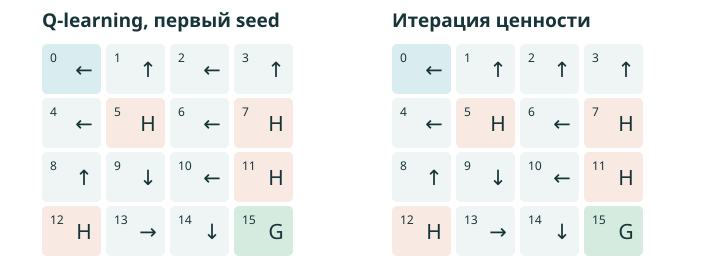

In [4]:
from IPython.display import SVG, display

q=tables[seeds[0]]
panels=(("Q-learning, первый seed",[greedy_action(row) for row in q]),
        ("Итерация ценности",dp_policy))
parts=[]
for i,(title,policy) in enumerate(panels):
    x0=42+350*i
    parts.append(f'<text x="{x0}" y="27" font-size="19" font-weight="bold">{title}</text>')
    for row,line in enumerate(GRID):
        for col,tile in enumerate(line):
            state=4*row+col
            x,y=x0+64*col,44+54*row
            fill={"S":"#d9edf0","F":"#eef5f4","H":"#f8e9e2","G":"#d6ebe0"}[tile]
            label=tile if tile in "HG" else ARROWS[policy[state]]
            parts.append(f'<rect x="{x}" y="{y}" width="59" height="50" rx="5" fill="{fill}"/>')
            parts.append(f'<text x="{x+8}" y="{y+18}" font-size="12">{state}</text>')
            parts.append(f'<text x="{x+42}" y="{y+33}" font-size="21" text-anchor="middle">{label}</text>')
svg=('<svg xmlns="http://www.w3.org/2000/svg" width="710" height="274" '
     'viewBox="0 0 710 274" font-family="sans-serif" fill="#173438">'
     '<rect width="710" height="274" fill="white"/>'
     +"".join(parts)+"</svg>")
display(SVG(svg))

## 3. Самостоятельная работа
**A.** Вычислите переходы из клетки 14 вправо и обновите Q после достижения цели.

**B.** Выполните полный профиль. Сравните успешные эпизоды, падения и таймауты для
каждого seed. Объясните, чем доля успехов отличается от дисконтированной ценности.

**C.** Повторите эксперимент в детерминированной среде или заранее измените
расписание исследования. Отделите результаты двух протоколов.